1. Análise Exploratória dos Dados

In [452]:
import pandas as pd
import numpy as np

df_funcionarios = pd.read_csv('/home/stephanie/Documentos/UFBA/LACEDA/Projeto-de-Nivelamento00---LACEDA-StephanieSacramento/dados/funcionarios.csv')
df_departamentos = pd.read_csv('/home/stephanie/Documentos/UFBA/LACEDA/Projeto-de-Nivelamento00---LACEDA-StephanieSacramento/dados/departamentos.csv')
df_filiais = pd.read_csv('/home/stephanie/Documentos/UFBA/LACEDA/Projeto-de-Nivelamento00---LACEDA-StephanieSacramento/dados/filiais.csv')

df_filiais['id_filial'] = df_filiais['id_filial'].astype(str)
df_funcionarios['id_filial'] = df_funcionarios['id_filial'].astype(str)

# Merge dos dataframes de funcionarios com departamentos e filiais
df_analise = pd.merge(df_funcionarios, df_departamentos, on='id_departamento', how='left')
df_analise = pd.merge(df_analise, df_filiais, on='id_filial', how='left')


In [453]:
display(df_analise.sample(10))

,id_colaborador,nome,genero,nivel,data_admissao,data_promocao,salario_base,percentual_bonus,id_departamento,id_filial,...,processos_actifs,horas_extras_mes,score_satisfacao,home_office,status_atual,nome_departamento,id_chefe_departamento,cidade,estado,id_socio_diretor
590,591,Vitor Xavier 591,Não-binário,Júnior,2025-07-18,NaN,3809.24,7,40,3,...,19,15,3.9,False,Ativo,Tributário,400,Rio de Janeiro,RJ,503
535,536,Vitor Xavier 536,Não-binário,Sênior,2021-02-14,NaN,13071.01,33,40,4,...,31,19,3.5,True,Ativo,Tributário,400,Belo Horizonte,MG,504
400,401,Mariana Rocha 401,Não-binário,Pleno,2021-02-02,NaN,7309.52,12,40,1,...,23,14,3.9,False,Desligado,Tributário,400,Salvador,BA,501
555,556,João Lima 556,Não-binário,Pleno,2022-07-26,NaN,7231.47,13,30,1,...,35,22,3.2,False,Desligado,Corporativo,300,Salvador,BA,501
608,609,Renata Pinto 609,Masculino,Pleno,2020-07-25,2022-04-08,5950.56,14,10,3,...,16,16,NaN,False,Ativo,Civil,100,Rio de Janeiro,RJ,503
402,403,João Lima 403,Feminino,Pleno,2022-08-30,NaN,7075.9,11,10,2,...,25,22,4.8,False,Desligado,Civil,100,São Paulo,SP,502
277,278,Mariana Rocha 278,Não-binário,Júnior,2025-02-19,NaN,4379.12,9,40,3,...,23,13,4.9,False,Ativo,Tributário,400,Rio de Janeiro,RJ,503
346,347,Isabela Carvalho 347,Masculino,Pleno,2022-12-26,NaN,6823.35,10,20,2,...,62,51,1.1,False,Desligado,Trabalhista,200,São Paulo,SP,502
619,620,Tatiana Mendes 620,Não-binário,Pleno,2023-06-16,NaN,7492.19,12,20,1,...,49,50,2.2,True,Ativo,Trabalhista,200,Salvador,BA,501
24,25,Diego Santos 25,Feminino,Júnior,2024-09-24,NaN,3767.85,6,40,3,...,31,18,3.4,False,Ativo,Tributário,400,Rio de Janeiro,RJ,503


In [454]:
df_analise.info()

<class 'pandas.DataFrame'>
RangeIndex: 650 entries, 0 to 649
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_colaborador         650 non-null    int64  
 1   nome                   650 non-null    str    
 2   genero                 650 non-null    str    
 3   nivel                  650 non-null    str    
 4   data_admissao          650 non-null    str    
 5   data_promocao          216 non-null    str    
 6   salario_base           650 non-null    str    
 7   percentual_bonus       650 non-null    int64  
 8   id_departamento        650 non-null    int64  
 9   id_filial              650 non-null    str    
 10  id_reporta_a           617 non-null    float64
 11  processos_actifs       650 non-null    int64  
 12  horas_extras_mes       650 non-null    int64  
 13  score_satisfacao       615 non-null    float64
 14  home_office            650 non-null    bool   
 15  status_atual     

In [455]:
#Estatísticas descritivas do DataFrame
df_analise.describe()

,id_colaborador,percentual_bonus,id_departamento,id_reporta_a,processos_actifs,horas_extras_mes,score_satisfacao,id_chefe_departamento,id_socio_diretor
count,650.00000,650.000000,650.000000,617.000000,650.000000,650.000000,615.000000,650.000000,650.000000
mean,325.50000,14.100000,25.538462,338.254457,32.096923,20.932308,3.463252,255.384615,502.496923
std,187.78312,11.204535,11.285723,148.196885,15.971030,16.337495,1.190878,112.857232,1.099442
min,1.00000,0.000000,10.000000,100.000000,12.000000,2.000000,1.000000,100.000000,501.000000
25%,163.25000,6.250000,20.000000,200.000000,20.000000,9.000000,2.250000,200.000000,502.000000
50%,325.50000,11.000000,30.000000,400.000000,28.000000,16.000000,3.800000,300.000000,502.000000
75%,487.75000,19.000000,40.000000,501.000000,45.750000,36.000000,4.400000,400.000000,503.000000
max,650.00000,55.000000,40.000000,502.000000,68.000000,58.000000,5.000000,400.000000,504.000000


In [456]:
# Verificando linhas duplicadas com base na coluna 'id_colaborador'
display(df_analise[df_analise.duplicated(subset=['id_colaborador'], keep=False)]) 

,id_colaborador,nome,genero,nivel,data_admissao,data_promocao,salario_base,percentual_bonus,id_departamento,id_filial,...,processos_actifs,horas_extras_mes,score_satisfacao,home_office,status_atual,nome_departamento,id_chefe_departamento,cidade,estado,id_socio_diretor


In [457]:
# Verificando inconsistências nas colunas 
print(df_analise["nivel"].unique())
print(df_analise["genero"].unique())
print(df_analise["id_departamento"].unique())
print(df_analise["id_filial"].unique())

<StringArray>
['Júnior', 'Pleno', 'Sênior', 'Sócio']
Length: 4, dtype: str
<StringArray>
['Não-binário', 'Masculino', 'Feminino', 'Fem']
Length: 4, dtype: str
[10 30 20 40]
<StringArray>
['1', '2', '3', '4']
Length: 4, dtype: str


In [458]:
print(df_analise['nivel'].value_counts())

nivel
Júnior    276
Pleno     246
Sênior     95
Sócio      33
Name: count, dtype: int64


In [459]:
# Visualizando as linhas com valores nulos na coluna 'id_reporta_a'
display(df_analise[df_analise['id_reporta_a'].isnull()])

,id_colaborador,nome,genero,nivel,data_admissao,data_promocao,salario_base,percentual_bonus,id_departamento,id_filial,...,processos_actifs,horas_extras_mes,score_satisfacao,home_office,status_atual,nome_departamento,id_chefe_departamento,cidade,estado,id_socio_diretor
41,42,Ana Silva 42,Masculino,Sócio,2013-01-16,2019-01-30,22652.44,50,40,4,...,22,13,4.5,True,Ativo,Tributário,400,Belo Horizonte,MG,504
56,57,Elena Rodrigues 57,Masculino,Sócio,21/07/2017,2020-05-23,18802.92,49,40,4,...,12,6,3.9,True,Ativo,Tributário,400,Belo Horizonte,MG,504
72,73,Vitor Xavier 73,Masculino,Sócio,2013-08-30,07/10/2016,23697.22,47,10,1,...,31,15,3.4,False,Ativo,Civil,100,Salvador,BA,501
80,81,Bruno Souza 81,Masculino,Sócio,2016-11-21,2019-09-06,21434.27,47,30,1,...,24,2,4.9,False,Ativo,Corporativo,300,Salvador,BA,501
102,103,Felipe Costa 103,Não-binário,Sócio,2017-08-06,2021-10-14,20082.32,49,10,1,...,34,17,3.6,True,Ativo,Civil,100,Salvador,BA,501
122,123,Kamila Pereira 123,Masculino,Sócio,2017-04-18,2020-04-24,25823.29,40,10,1,...,27,22,3.6,False,Ativo,Civil,100,Salvador,BA,501
139,140,Gabriela Almeida 140,Masculino,Sócio,2015-09-25,2020-03-02,25696.62,38,20,2,...,67,41,1.6,False,Ativo,Trabalhista,200,São Paulo,SP,502
142,143,Pedro Gomes 143,Masculino,Sócio,2017-03-02,2020-05-17,22372.37,40,30,3,...,14,3,4.6,False,Ativo,Corporativo,300,Rio de Janeiro,RJ,503
154,155,Vitor Xavier 155,Masculino,Sócio,11/07/2013,2019-08-19,"R$ 20513,47",47,40,3,...,27,20,4.6,False,Ativo,Tributário,400,Rio de Janeiro,RJ,503
160,161,Olivia Barbosa 161,Masculino,Sócio,2015-07-30,2018-09-09,24793.44,55,40,1,...,35,9,4.1,False,Ativo,Tributário,400,Salvador,BA,501


In [460]:
# Visualizando as linhas com valores nulos na coluna 'id_reporta_a'
display(df_analise[df_analise['score_satisfacao'].isnull()])

,id_colaborador,nome,genero,nivel,data_admissao,data_promocao,salario_base,percentual_bonus,id_departamento,id_filial,...,processos_actifs,horas_extras_mes,score_satisfacao,home_office,status_atual,nome_departamento,id_chefe_departamento,cidade,estado,id_socio_diretor
0,1,Isabela Carvalho 1,Não-binário,Júnior,07/09/2024,NaN,"R$ 3834,82",0,10,1,...,14,8,NaN,False,Ativo,Civil,100,Salvador,BA,501
19,20,Samuel Teixeira 20,Feminino,Júnior,2024-06-08,NaN,3908.52,7,30,1,...,20,3,NaN,False,Ativo,Corporativo,300,Salvador,BA,501
38,39,Natan Alves 39,Feminino,Júnior,2025-05-16,NaN,3658.31,8,10,3,...,32,10,NaN,True,Ativo,Civil,100,Rio de Janeiro,RJ,503
57,58,Isabela Carvalho 58,Masculino,Pleno,2021-11-24,2023-10-09,7449.51,15,20,1,...,67,50,NaN,True,Ativo,Trabalhista,200,Salvador,BA,501
76,77,Felipe Costa 77,Feminino,Sênior,2018-07-14,2023-07-13,10316.33,22,10,3,...,12,4,NaN,False,Desligado,Civil,100,Rio de Janeiro,RJ,503
95,96,Samuel Teixeira 96,Não-binário,Júnior,2025-06-03,NaN,4679.62,4,30,1,...,35,2,NaN,False,Ativo,Corporativo,300,Salvador,BA,501
114,115,Samuel Teixeira 115,Masculino,Sênior,2019-01-19,2023-01-18,11750.35,30,40,3,...,26,6,NaN,True,Ativo,Tributário,400,Rio de Janeiro,RJ,503
133,134,João Lima 134,Feminino,Júnior,19/04/2025,NaN,4510.25,2,20,1,...,53,41,NaN,False,Ativo,Trabalhista,200,Salvador,BA,501
152,153,Samuel Teixeira 153,Não-binário,Júnior,2024-09-05,NaN,4357.94,2,40,1,...,14,7,NaN,True,Ativo,Tributário,400,Salvador,BA,501
171,172,Lucas Martins 172,Não-binário,Júnior,2025-04-10,NaN,4925.38,10,40,3,...,34,13,NaN,False,Ativo,Tributário,400,Rio de Janeiro,RJ,503


2. Polimento dos Dados
- Padronização das colunas e correção de incosistências nos dados.

In [461]:
# Corrigindo tipo de dado da coluna 'salario_base'  
df_analise['salario_base'] = df_analise['salario_base'].replace("[^0-9.]", "", regex=True).astype(float)

In [462]:
# Correção de inconsistências na coluna 'genero'
df_analise["genero"] = df_analise["genero"]

ajustar = {
    "Fem": "Feminino"
}

df_analise["genero"] = df_analise["genero"].replace(ajustar)

print(df_analise["genero"].unique())

<StringArray>
['Não-binário', 'Masculino', 'Feminino']
Length: 3, dtype: str


In [463]:
# Correção da coluna 'nome' para remover as ids no final do nome
df_analise["nome"] = df_analise["nome"].str.replace(r'\d+', '', regex=True).str.strip()

df_analise.head(10)

,id_colaborador,nome,genero,nivel,data_admissao,data_promocao,salario_base,percentual_bonus,id_departamento,id_filial,...,processos_actifs,horas_extras_mes,score_satisfacao,home_office,status_atual,nome_departamento,id_chefe_departamento,cidade,estado,id_socio_diretor
0,1,Isabela Carvalho,Não-binário,Júnior,07/09/2024,NaN,383482.00,0,10,1,...,14,8,NaN,False,Ativo,Civil,100,Salvador,BA,501
1,2,Samuel Teixeira,Não-binário,Pleno,2022-05-09,NaN,7267.80,15,10,2,...,16,8,4.9,True,Desligado,Civil,100,São Paulo,SP,502
2,3,Diego Santos,Masculino,Júnior,2025-01-02,NaN,4771.24,1,10,1,...,29,11,4.7,True,Ativo,Civil,100,Salvador,BA,501
3,4,Carla Oliveira,Não-binário,Pleno,2020-04-03,NaN,7819.21,14,30,2,...,32,13,3.5,False,Desligado,Corporativo,300,São Paulo,SP,502
4,5,Carla Oliveira,Não-binário,Júnior,2025-09-15,NaN,4452.47,5,20,3,...,46,42,2.2,False,Desligado,Trabalhista,200,Rio de Janeiro,RJ,503
5,6,Gabriela Almeida,Feminino,Júnior,2025-08-03,NaN,4814.55,4,40,3,...,16,9,4.5,True,Ativo,Tributário,400,Rio de Janeiro,RJ,503
6,7,Mariana Rocha,Não-binário,Júnior,2025-01-05,NaN,3828.98,10,30,4,...,17,15,4.3,True,Ativo,Corporativo,300,Belo Horizonte,MG,504
7,8,Isabela Carvalho,Não-binário,Pleno,07/02/2023,NaN,5534.44,20,40,4,...,15,11,4.0,True,Desligado,Tributário,400,Belo Horizonte,MG,504
8,9,Felipe Costa,Não-binário,Pleno,2022-11-05,2023-12-29,6395.33,12,10,3,...,28,2,4.3,True,Ativo,Civil,100,Rio de Janeiro,RJ,503
9,10,João Lima,Masculino,Pleno,2021-05-05,NaN,8134.03,18,10,1,...,16,17,4.9,False,Desligado,Civil,100,Salvador,BA,501


In [464]:
#Tranformando as colunas de Ids para String
df_analise['id_colaborador'] = df_analise['id_colaborador'].astype(str)   
df_analise['id_reporta_a'] = df_analise['id_reporta_a'].astype(str)
df_analise['id_departamento'] = df_analise['id_departamento'].astype(str)
df_analise['id_chefe_departamento'] = df_analise['id_chefe_departamento'].astype(str)
df_analise['id_socio_diretor'] = df_analise['id_socio_diretor'].astype(str)

#Preenchendo valores nulos da coluna 'id_reporta_a' com "Sem gestor"
df_analise['id_reporta_a'] = df_analise['id_reporta_a'].fillna("Sem gestor")

In [465]:
# Formatação da coluna 'data_promocao' e 'data_admissao' para o tipo datetime
df_analise['data_promocao'] = pd.to_datetime(df_analise['data_promocao'], format='mixed', dayfirst=True, errors='coerce')
df_analise['data_admissao'] = pd.to_datetime(df_analise['data_admissao'], format='mixed', dayfirst=True, errors='coerce')

display(df_analise.sample(10)) 
display(df_analise.info())

,id_colaborador,nome,genero,nivel,data_admissao,data_promocao,salario_base,percentual_bonus,id_departamento,id_filial,...,processos_actifs,horas_extras_mes,score_satisfacao,home_office,status_atual,nome_departamento,id_chefe_departamento,cidade,estado,id_socio_diretor
177,178,Tatiana Mendes,Feminino,Júnior,2025-01-28,NaT,4027.30,8,10,2,...,31,21,4.5,True,Ativo,Civil,100,São Paulo,SP,502
486,487,Isabela Carvalho,Masculino,Pleno,2023-09-05,2024-09-13,6640.46,10,10,1,...,35,19,4.2,True,Ativo,Civil,100,Salvador,BA,501
194,195,Mariana Rocha,Feminino,Pleno,2023-10-31,NaT,6561.83,10,40,4,...,31,21,3.6,True,Ativo,Tributário,400,Belo Horizonte,MG,504
109,110,Mariana Rocha,Não-binário,Pleno,2021-01-09,NaT,7565.84,15,40,2,...,16,12,4.8,True,Desligado,Tributário,400,São Paulo,SP,502
232,233,Isabela Carvalho,Masculino,Júnior,2025-04-20,NaT,3575.12,1,20,4,...,48,36,1.0,True,Desligado,Trabalhista,200,Belo Horizonte,MG,504
145,146,Mariana Rocha,Masculino,Júnior,2024-03-21,NaT,4059.58,1,30,3,...,32,22,4.6,False,Ativo,Corporativo,300,Rio de Janeiro,RJ,503
425,426,João Lima,Não-binário,Pleno,2022-01-14,NaT,6105.28,14,30,2,...,13,11,5.0,False,Desligado,Corporativo,300,São Paulo,SP,502
557,558,Diego Santos,Feminino,Pleno,2021-08-05,NaT,6408.07,17,40,2,...,24,10,4.3,False,Desligado,Tributário,400,São Paulo,SP,502
384,385,Gabriela Almeida,Feminino,Sênior,2020-02-06,2026-01-06,11559.83,28,10,4,...,16,3,4.4,False,Ativo,Civil,100,Belo Horizonte,MG,504
601,602,Hugo Ribeiro,Feminino,Pleno,2020-04-24,2021-03-07,7587.34,10,40,2,...,33,20,3.3,True,Ativo,Tributário,400,São Paulo,SP,502


<class 'pandas.DataFrame'>
RangeIndex: 650 entries, 0 to 649
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id_colaborador         650 non-null    str           
 1   nome                   650 non-null    str           
 2   genero                 650 non-null    str           
 3   nivel                  650 non-null    str           
 4   data_admissao          650 non-null    datetime64[us]
 5   data_promocao          216 non-null    datetime64[us]
 6   salario_base           650 non-null    float64       
 7   percentual_bonus       650 non-null    int64         
 8   id_departamento        650 non-null    str           
 9   id_filial              650 non-null    str           
 10  id_reporta_a           650 non-null    str           
 11  processos_actifs       650 non-null    int64         
 12  horas_extras_mes       650 non-null    int64         
 13  score_satisfacao

None

- Descobrindo outliers

In [466]:
#Identificação de outliers com IQR (Intervalo Interquartil)

outliers = {}

#Filtrando colunas numéricas
for col in df_analise.select_dtypes(include=["float64", "int64"]).columns:
    Q1 = df_analise[col].quantile(0.25)
    Q3 = df_analise[col].quantile(0.75)
    IQR = Q3 - Q1                 
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    filtro = (df_analise[col] < limite_inferior) | (df_analise[col] > limite_superior)
    contagem_outliers = filtro.sum()
#Contando a quantidade de outliers por coluna
    if contagem_outliers > 0:
        menor_valor = df_analise.loc[filtro, col].min()
        maior_valor = df_analise.loc[filtro, col].max()
    else:
        menor_valor = None
        maior_valor = None 
#Construindo um dataframe com as informações de outliers
    outliers[col] = {
        "Contagem de Outliers": contagem_outliers,
        "Percentual de Outliers": ((contagem_outliers / len(df_analise)) * 100).round(3),
        "Menor Outlier": menor_valor,
        "Maior Outlier": maior_valor,
        "Limite Inferior": limite_inferior.round(3),
        "Limite Superior": limite_superior.round(3)
    }

outliers_df = pd.DataFrame.from_dict(outliers, orient='index')  
outliers_df.head(10)



,Contagem de Outliers,Percentual de Outliers,Menor Outlier,Maior Outlier,Limite Inferior,Limite Superior
salario_base,82,12.615,19766.38,2051347.0,-4627.368,19571.812
percentual_bonus,27,4.154,39.00,55.0,-12.875,38.125
processos_actifs,0,0.000,NaN,NaN,-18.625,84.375
horas_extras_mes,0,0.000,NaN,NaN,-31.500,76.500
score_satisfacao,0,0.000,NaN,NaN,-0.975,7.625


In [467]:
# Identificação de outliers por nível
resumo_outliers_nivel = []

for nivel in df_analise['nivel'].unique():
    df_nivel = df_analise[df_analise['nivel'] == nivel]['salario_base']
    
    Q1 = df_nivel.quantile(0.25)
    Q3 = df_nivel.quantile(0.75)
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    outliers = df_nivel[(df_nivel < limite_inferior) | (df_nivel > limite_superior)]
    
    resumo_outliers_nivel.append({
        'nivel': nivel,
        'quantidade_outliers': len(outliers),
        'limite_inferior': limite_inferior.round(2),
        'limite_superior': limite_superior.round(2),
        'menor_outlier': outliers.min() if len(outliers) > 0 else None,
        'maior_outlier': outliers.max() if len(outliers) > 0 else None
    })

resumo_outliers = pd.DataFrame(resumo_outliers_nivel)
display(resumo_outliers)

,nivel,quantidade_outliers,limite_inferior,limite_superior,menor_outlier,maior_outlier
0,Júnior,33,2682.10,6038.75,39067.0,492767.0
1,Pleno,22,3840.76,10487.85,56872.0,839042.0
2,Sênior,4,7316.46,16138.54,116730.0,1348884.0
3,Sócio,1,12066.04,30675.93,2051347.0,2051347.0


- Tratando Outliers da coluna 'salario_base' através da mediana do seu nível

In [468]:
# Calculando a mediana do salário base por nível
for _, dado in resumo_outliers.iterrows():
    nivel = dado['nivel']   
    limite_inferior = dado['limite_inferior']
    limite_superior = dado['limite_superior']   

    salarios = df_analise[df_analise['nivel'] == nivel]['salario_base']

    mediana = salarios[(salarios >= limite_inferior) & (salarios <= limite_superior)].median()

    mascara_outliers = (df_analise['nivel'] == nivel) & ((df_analise['salario_base'] < limite_inferior) | (df_analise['salario_base'] > limite_superior))

   # Corrigindon os outliers
    df_analise.loc[mascara_outliers, 'salario_base'] = mediana

3. Engenharia de Dados
- Criar novas colunas

In [469]:
# Criando uma nova coluna 'flag_desligamento' mapeeando os valores da coluna 'status_atual' para 1 (Desligado) e 0 (Ativo)
df_analise['flag_desligamento'] = np.where(df_analise['status_atual'] == 'Desligado', 1, 0)

In [470]:
# Criando uma nova coluna 'flag_promocao' mapeando os valores da coluna 'data_promocao' para 1 (Já promovido) e 0 (Nunca promovido)
df_analise['flag_promocao'] = np.where(df_analise['data_promocao'].isnull(), 0, 1)

In [471]:
# Criando uma nova coluna 'faixa_horas_extras' 
df_analise['faixa_horas_extras'] = pd.cut(
    df_analise['horas_extras_mes'],
    bins=[0, 10, 20, 35, 60],
    labels=['0-10h', '11-20h', '21-35h', '36-60h']
)

In [472]:
# Criando uma nova coluna 'faixa_processos'

df_analise['faixa_processos'] = pd.cut(
    df_analise['processos_actifs'],
    bins=[0, 20, 30, 45, 100],
    labels=['12-20h', '21-30h', '31-45h', '46-70h']
)

In [473]:
# Criando uma nova coluna 'ano_admissao'
df_analise['ano_admissao'] = df_analise['data_admissao'].dt.year

display(df_analise[['nome', 'data_admissao', 'ano_admissao', 'status_atual', 'flag_desligamento']].sample(10))

,nome,data_admissao,ano_admissao,status_atual,flag_desligamento
61,Gabriela Almeida,2022-02-26,2022,Desligado,1
82,Lucas Martins,2025-10-22,2025,Ativo,0
58,João Lima,2024-08-20,2024,Ativo,0
114,Samuel Teixeira,2019-01-19,2019,Ativo,0
151,Felipe Costa,2022-01-06,2022,Desligado,1
628,Tatiana Mendes,2024-05-06,2024,Ativo,0
205,Felipe Costa,2020-05-28,2020,Desligado,1
385,Olivia Barbosa,2019-07-29,2019,Ativo,0
196,Tatiana Mendes,2019-10-26,2019,Ativo,0
337,Natan Alves,2022-10-12,2022,Desligado,1


4. Analisar/Filtrar os dados

O que quero analisar:
- Evasão por departamento
- Evasão por filial
- Evasão por numero de horas extra 
- Evasão por quantidade de processos 
- Evasão por salario
- Evasão po Nivel
- Evasão por promoção

- Relação do score com essas variaveis acima

In [474]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11

In [475]:
display(df_analise["horas_extras_mes"].sort_values().unique())

array([ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18,
       19, 20, 21, 22, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47,
       48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58])

- analises por agrupamento de dados

In [476]:
# Analise da porgentagem de evasão por departamento  

evasao_departamentos = df_analise.groupby('nome_departamento')['flag_desligamento'].agg(
    total='count',
    desligados='sum',
    taxa_evasao='mean'
).reset_index()

evasao_departamentos['% taxa_evasao'] = (evasao_departamentos['taxa_evasao'] * 100).round(2)
evasao_departamentos = evasao_departamentos.sort_values(by='% taxa_evasao', ascending=False).reset_index(drop=True)

display(evasao_departamentos)


,nome_departamento,total,desligados,taxa_evasao,% taxa_evasao
0,Trabalhista,170,74,0.435294,43.53
1,Tributário,182,50,0.274725,27.47
2,Civil,151,28,0.185430,18.54
3,Corporativo,147,25,0.170068,17.01


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

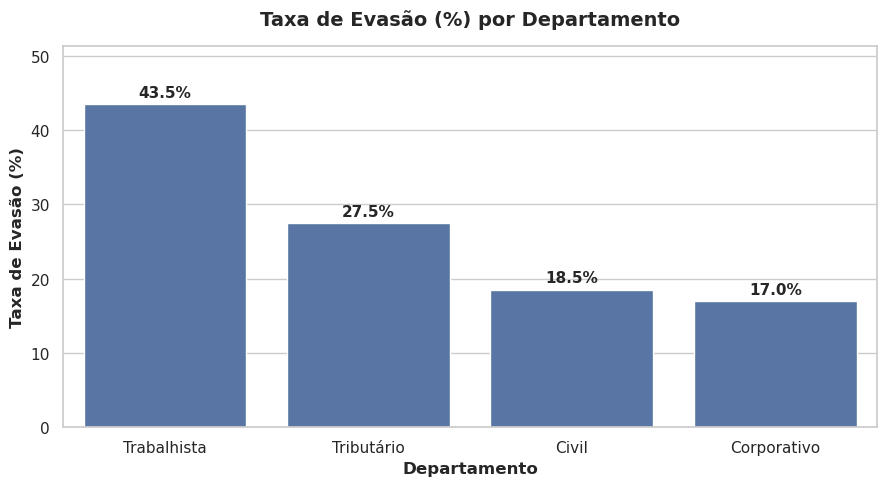

In [477]:
#Grafico evasao por departamento

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=evasao_departamentos,
    x='nome_departamento',
    y='% taxa_evasao'
)

plt.title('Taxa de Evasão (%) por Departamento', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Departamento', fontweight='bold')
plt.ylabel('Taxa de Evasão (%)', fontweight='bold')
plt.ylim(0, evasao_departamentos['% taxa_evasao'].max() * 1.18)

ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/evasao_departamento.png', dpi=300, bbox_inches='tight')
plt.show()

In [478]:
# Analise da porgentagem de evasão por filial

evasao_filiais = df_analise.groupby(['estado', 'cidade'])['flag_desligamento'].agg(
    total='count',
    desligados='sum',
    taxa_evasao='mean'
).reset_index()
evasao_filiais['% taxa_evasao'] = (evasao_filiais['taxa_evasao'] * 100).round(2)

display(evasao_filiais)

,estado,cidade,total,desligados,taxa_evasao,% taxa_evasao
0,BA,Salvador,155,41,0.264516,26.45
1,MG,Belo Horizonte,156,37,0.237179,23.72
2,RJ,Rio de Janeiro,166,49,0.295181,29.52
3,SP,São Paulo,173,50,0.289017,28.90


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

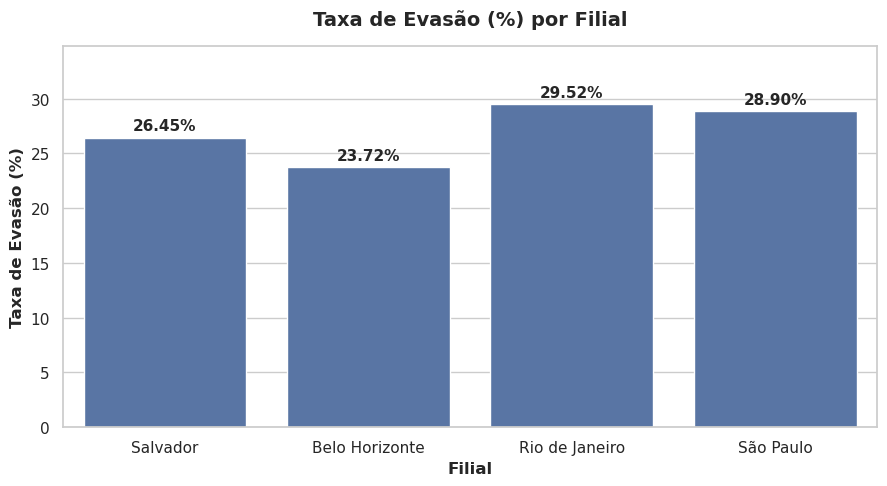

In [479]:
# Grafico evasão por filial

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=evasao_filiais,
    x='cidade',
    y='% taxa_evasao'
)

plt.title('Taxa de Evasão (%) por Filial', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Filial', fontweight='bold')
plt.ylabel('Taxa de Evasão (%)', fontweight='bold')
plt.ylim(0, evasao_filiais['% taxa_evasao'].max() * 1.18)

ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/evasao_filial.png', dpi=300, bbox_inches='tight')
plt.show()

In [480]:
# Análise de evasão por gestor direto

evasao_gestor = df_analise.groupby('id_reporta_a')['flag_desligamento'].agg(
    total_liderados='count',
    desligados='sum',
    taxa_evasao='mean'
).reset_index()
evasao_gestor['% taxa_evasao'] = (evasao_gestor['taxa_evasao'] * 100).round(2)

display(evasao_gestor)

,id_reporta_a,total_liderados,desligados,taxa_evasao,% taxa_evasao
0,100.0,103,29,0.281553,28.16
1,200.0,89,28,0.314607,31.46
2,300.0,98,28,0.285714,28.57
3,400.0,126,39,0.309524,30.95
4,501.0,99,30,0.303030,30.30
5,502.0,102,23,0.225490,22.55
6,Sem gestor,33,0,0.000000,0.00


In [481]:
# Análise da evasão por nível
evasao_nivel = df_analise.groupby('nivel')['flag_desligamento'].agg(
    total_colaboradores='count',
    total_desligamentos='sum',
    taxa_evasao='mean'
).reset_index()

evasao_nivel['% taxa_evasao'] = (evasao_nivel['taxa_evasao'] * 100).round(2)
evasao_nivel = evasao_nivel.sort_values(by='% taxa_evasao', ascending=False)

display(evasao_nivel)

,nivel,total_colaboradores,total_desligamentos,taxa_evasao,% taxa_evasao
1,Pleno,246,116,0.471545,47.15
2,Sênior,95,18,0.189474,18.95
0,Júnior,276,43,0.155797,15.58
3,Sócio,33,0,0.000000,0.00


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

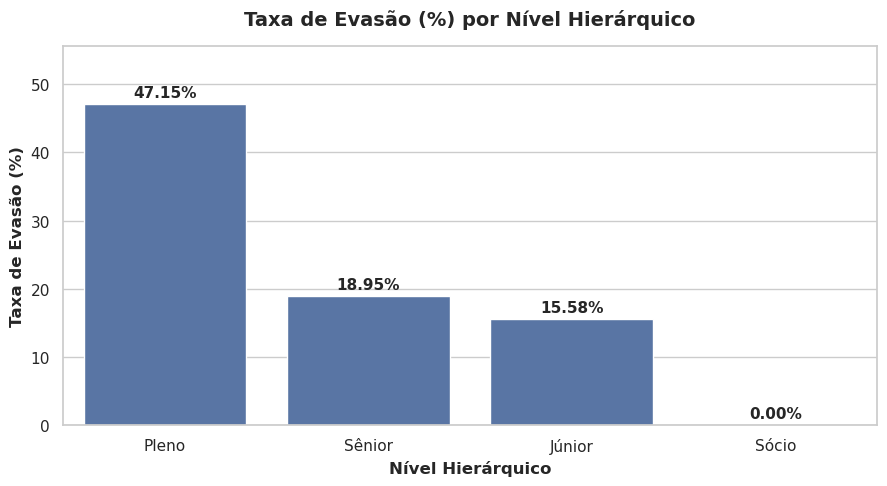

In [482]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=evasao_nivel,
    x='nivel',
    y='% taxa_evasao'
)

plt.title('Taxa de Evasão (%) por Nível Hierárquico', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Nível Hierárquico', fontweight='bold')
plt.ylabel('Taxa de Evasão (%)', fontweight='bold')
plt.ylim(0, evasao_nivel['% taxa_evasao'].max() * 1.18)

ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/evasao_nivel.png', dpi=300, bbox_inches='tight')
plt.show()

In [483]:
# Analises de evasao por nivel e promoção
analise_promocao = df_analise.groupby(['nivel', 'flag_promocao'])['flag_desligamento'].agg(
    total='count',
    desligados='sum',
    taxa_evasao='mean'
).reset_index()

analise_promocao['% taxa_evasao'] = (analise_promocao['taxa_evasao'] * 100).round(2)
analise_promocao['status_promocao'] = analise_promocao['flag_promocao'].map({0: 'Nunca Promovido', 1: 'Já Promovido'})

display(analise_promocao)

,nivel,flag_promocao,total,desligados,taxa_evasao,% taxa_evasao,status_promocao
0,Júnior,0,276,43,0.155797,15.58,Nunca Promovido
1,Pleno,0,147,115,0.782313,78.23,Nunca Promovido
2,Pleno,1,99,1,0.010101,1.01,Já Promovido
3,Sênior,0,11,1,0.090909,9.09,Nunca Promovido
4,Sênior,1,84,17,0.202381,20.24,Já Promovido
5,Sócio,1,33,0,0.000000,0.00,Já Promovido


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

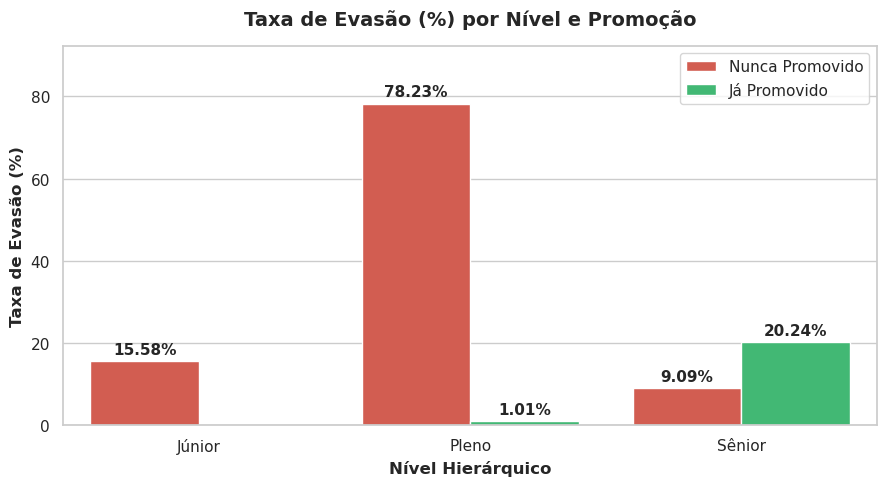

In [484]:
# Grafico de evasao por nivel e promoção
df_grafico = analise_promocao[analise_promocao['nivel'] != 'Sócio']

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=df_grafico,
    x='nivel',
    y='% taxa_evasao',
    hue='status_promocao',
    palette=['#e74c3c', '#2ecc71']
)

plt.title('Taxa de Evasão (%) por Nível e Promoção', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Nível Hierárquico', fontweight='bold')
plt.ylabel('Taxa de Evasão (%)', fontweight='bold')
plt.legend(title='')
plt.ylim(0, df_grafico['% taxa_evasao'].max() * 1.18)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/evasao_nivel_promocao.png', dpi=300, bbox_inches='tight')
plt.show()

In [485]:
# Analise da porgentagem de evasão se promovido ou não

evasao_promocao = df_analise.groupby('flag_promocao')['flag_desligamento'].agg(
    total='count',
    desligados='sum',
    taxa_evasao='mean'
).reset_index()

evasao_promocao['% taxa_evasao'] = (evasao_promocao['taxa_evasao'] * 100).round(2)
evasao_promocao['status_promocao'] = evasao_promocao['flag_promocao'].map({0: 'Nunca Promovido', 1: 'Já Promovido'}) 

display(evasao_promocao)

,flag_promocao,total,desligados,taxa_evasao,% taxa_evasao,status_promocao
0,0,434,159,0.366359,36.64,Nunca Promovido
1,1,216,18,0.083333,8.33,Já Promovido


- Analises temporais

In [486]:
# Analise por ano de contratação

evasao_safra = df_analise.groupby('ano_admissao')['flag_desligamento'].agg(
    total_contratados='count',
    total_desligados='sum',
    taxa_evasao='mean'
).reset_index()

evasao_safra['% taxa_evasao'] = (evasao_safra['taxa_evasao'] * 100).round(2)

display(evasao_safra)

,ano_admissao,total_contratados,total_desligados,taxa_evasao,% taxa_evasao
0,2012,6,0,0.000000,0.00
1,2013,10,0,0.000000,0.00
2,2014,3,0,0.000000,0.00
3,2015,3,0,0.000000,0.00
4,2016,3,0,0.000000,0.00
5,2017,21,0,0.000000,0.00
6,2018,20,5,0.250000,25.00
7,2019,26,5,0.192308,19.23
8,2020,77,41,0.532468,53.25
9,2021,73,32,0.438356,43.84


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

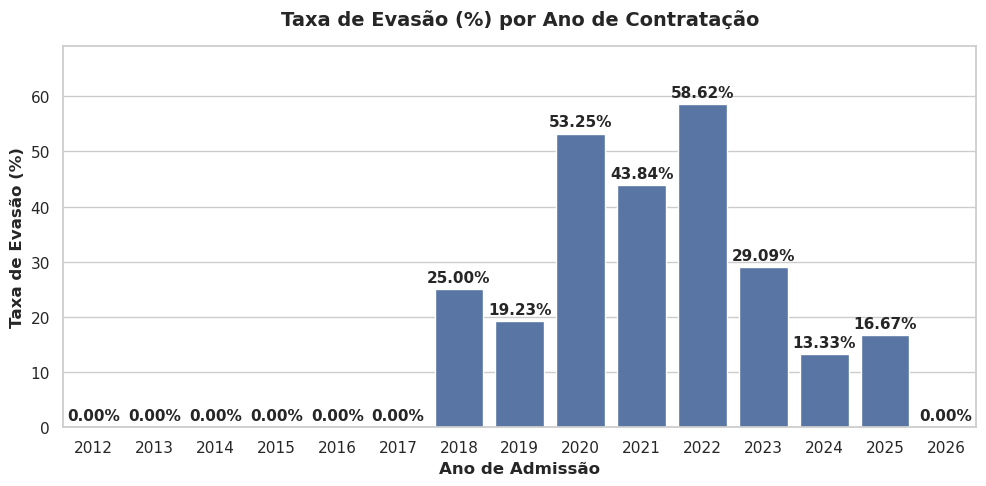

In [487]:
# Grafico de evasao por ano de contratação
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=evasao_safra,
    x='ano_admissao',
    y='% taxa_evasao'
)

plt.title('Taxa de Evasão (%) por Ano de Contratação', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ano de Admissão', fontweight='bold')
plt.ylabel('Taxa de Evasão (%)', fontweight='bold')
plt.ylim(0, evasao_safra['% taxa_evasao'].max() * 1.18)

ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/evasao_ano_contratacao.png', dpi=300, bbox_inches='tight')
plt.show()

In [488]:
# Análise da Evasão por Horas Extras

evasao_horas = df_analise.groupby('faixa_horas_extras')['flag_desligamento'].agg(
    total='count',
    desligados='sum',
    taxa_evasao='mean'
).reset_index()

evasao_horas['% taxa_evasao'] = (evasao_horas['taxa_evasao'] * 100).round(2)

display(evasao_horas)

,faixa_horas_extras,total,desligados,taxa_evasao,% taxa_evasao
0,0-10h,196,42,0.214286,21.43
1,11-20h,242,49,0.202479,20.25
2,21-35h,48,16,0.333333,33.33
3,36-60h,164,70,0.426829,42.68


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

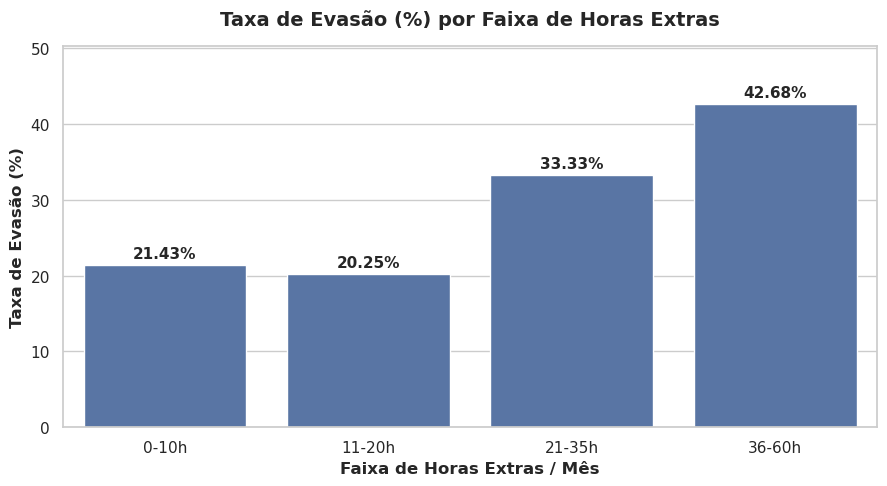

In [489]:
# Grafico de evasao por horas extras
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=evasao_horas,
    x='faixa_horas_extras',
    y='% taxa_evasao'
)

plt.title('Taxa de Evasão (%) por Faixa de Horas Extras', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Faixa de Horas Extras / Mês', fontweight='bold')
plt.ylabel('Taxa de Evasão (%)', fontweight='bold')
plt.ylim(0, evasao_horas['% taxa_evasao'].max() * 1.18)

ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/evasao_horas_extras.png', dpi=300, bbox_inches='tight')
plt.show()

In [490]:
# Análise da Evasão por Nível e Horas Extras

evasao_nivel_horas = df_analise.groupby(['nivel', 'faixa_horas_extras'])['flag_desligamento'].agg(
    total='count',
    desligados='sum',
    taxa_evasao='mean'
).reset_index()

evasao_nivel_horas['% taxa_evasao'] = (evasao_nivel_horas['taxa_evasao'] * 100).round(2)

display(evasao_nivel_horas)

,nivel,faixa_horas_extras,total,desligados,taxa_evasao,% taxa_evasao
0,Júnior,0-10h,82,0,0.000000,0.00
1,Júnior,11-20h,93,0,0.000000,0.00
2,Júnior,21-35h,22,1,0.045455,4.55
3,Júnior,36-60h,79,42,0.531646,53.16
4,Pleno,0-10h,72,34,0.472222,47.22
5,Pleno,11-20h,95,42,0.442105,44.21
6,Pleno,21-35h,22,13,0.590909,59.09
7,Pleno,36-60h,57,27,0.473684,47.37
8,Sênior,0-10h,31,8,0.258065,25.81
9,Sênior,11-20h,39,7,0.179487,17.95


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

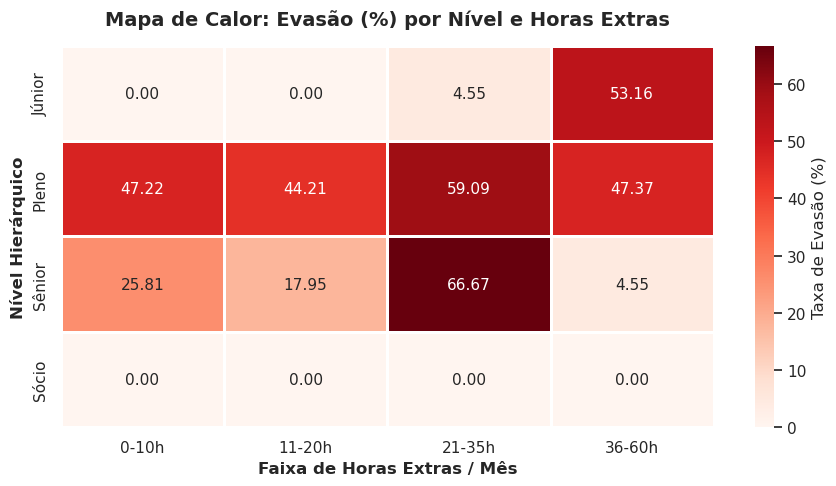

In [491]:
# Grafico de evasao por nivel e horas extras
matriz_evasao = evasao_nivel_horas.pivot(index='nivel', columns='faixa_horas_extras', values='% taxa_evasao')

plt.figure(figsize=(9, 5))
sns.heatmap(
    matriz_evasao,
    annot=True,
    fmt='.2f',
    cmap='Reds',
    linewidths=1,
    linecolor='white',
    cbar_kws={'label': 'Taxa de Evasão (%)'}
)

plt.title('Mapa de Calor: Evasão (%) por Nível e Horas Extras', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Faixa de Horas Extras / Mês', fontweight='bold')
plt.ylabel('Nível Hierárquico', fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/evasao_nivel_horas_extras_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

In [492]:
# Análise de evasão por processos ativos

evasao_processos = df_analise.groupby('faixa_processos')['flag_desligamento'].agg(
    total='count',
    desligados='sum',
    taxa_evasao='mean'
).reset_index()

evasao_processos['% taxa_evasao'] = (evasao_processos['taxa_evasao'] * 100).round(2)
display(evasao_processos)

,faixa_processos,total,desligados,taxa_evasao,% taxa_evasao
0,12-20h,170,39,0.229412,22.94
1,21-30h,209,47,0.224880,22.49
2,31-45h,108,19,0.175926,17.59
3,46-70h,163,72,0.441718,44.17


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

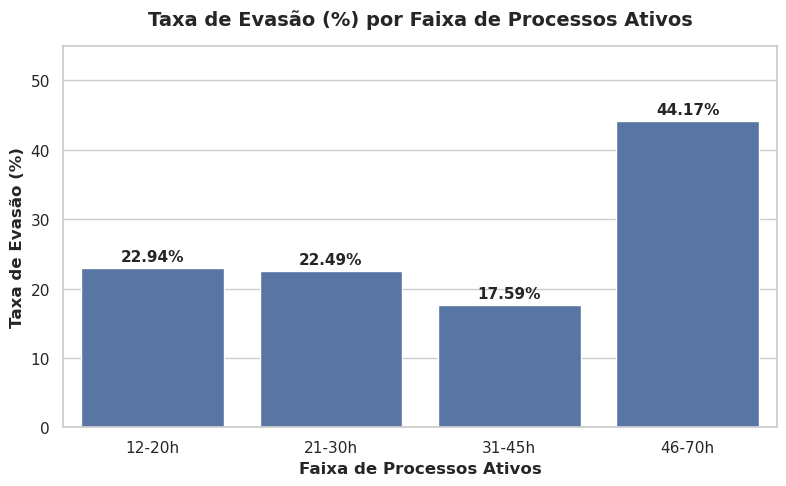

In [493]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=evasao_processos,
    x='faixa_processos',
    y='% taxa_evasao'
)

plt.title('Taxa de Evasão (%) por Faixa de Processos Ativos', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Faixa de Processos Ativos', fontweight='bold')
plt.ylabel('Taxa de Evasão (%)', fontweight='bold')
plt.ylim(0, 55)

# Rótulos com as porcentagens no topo de cada barra
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/evasao_faixa_processos.png', dpi=300, bbox_inches='tight')
plt.show()

In [494]:
# Análise da satisfação cruzada por nível, promoção e desligamento
df_satisfacao = df_analise[df_analise['nivel'] != 'Sócio'].groupby(
    ['nivel', 'flag_promocao', 'status_atual']
)['score_satisfacao'].mean().reset_index()

df_satisfacao['status_promocao'] = df_satisfacao['flag_promocao'].map({0: 'Sem Promoção', 1: 'Com Promoção'})
df_satisfacao['categoria'] = df_satisfacao['nivel'] + ' (' + df_satisfacao['status_promocao'] + ')'

matriz_satisfacao = df_satisfacao.pivot(
    index='categoria', 
    columns='status_atual', 
    values='score_satisfacao'
)

display(matriz_satisfacao)

status_atual,Ativo,Desligado
categoria,,
Júnior (Sem Promoção),3.695000,1.628571
Pleno (Com Promoção),3.450000,5.000000
Pleno (Sem Promoção),3.861290,3.484259
Sênior (Com Promoção),3.592063,3.631250
Sênior (Sem Promoção),3.060000,3.400000


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

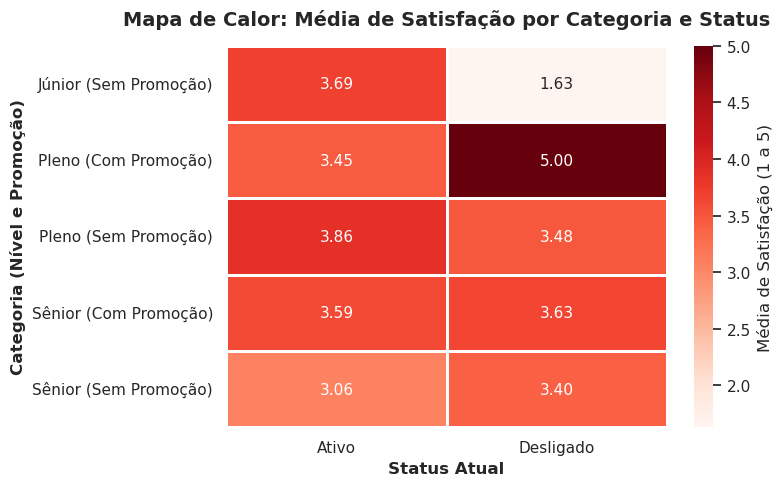

In [495]:
# Grafico de satisfacao por nivel, promoção e desligamento
plt.figure(figsize=(8, 5))
sns.heatmap(
    matriz_satisfacao,
    annot=True,
    fmt='.2f',
    cmap='Reds',
    linewidths=1,
    linecolor='white',
    cbar_kws={'label': 'Média de Satisfação (1 a 5)'}
)

plt.title('Mapa de Calor: Média de Satisfação por Categoria e Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Status Atual', fontweight='bold')
plt.ylabel('Categoria (Nível e Promoção)', fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/satisfacao_nivel_promocao_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

In [496]:
# Análise da evasão levando em conta as horas extras, home_office 

evasao_operacional = df_analise.groupby(['faixa_horas_extras', 'home_office'], observed=False).agg(
    total_colaboradores=('flag_desligamento', 'count'),
    satisfacao_media=('score_satisfacao', 'mean'),
    taxa_evasao=('flag_desligamento', 'mean')
).reset_index().round(2)

evasao_operacional['% taxa_evasao'] = (evasao_operacional['taxa_evasao'] * 100).round(2)

display(evasao_operacional)

,faixa_horas_extras,home_office,total_colaboradores,satisfacao_media,taxa_evasao,% taxa_evasao
0,0-10h,False,113,4.08,0.23,23.0
1,0-10h,True,83,4.11,0.19,19.0
2,11-20h,False,149,4.11,0.22,22.0
3,11-20h,True,93,4.15,0.17,17.0
4,21-35h,False,28,4.09,0.29,29.0
5,21-35h,True,20,3.70,0.40,40.0
6,36-60h,False,95,1.64,0.38,38.0
7,36-60h,True,69,1.69,0.49,49.0


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

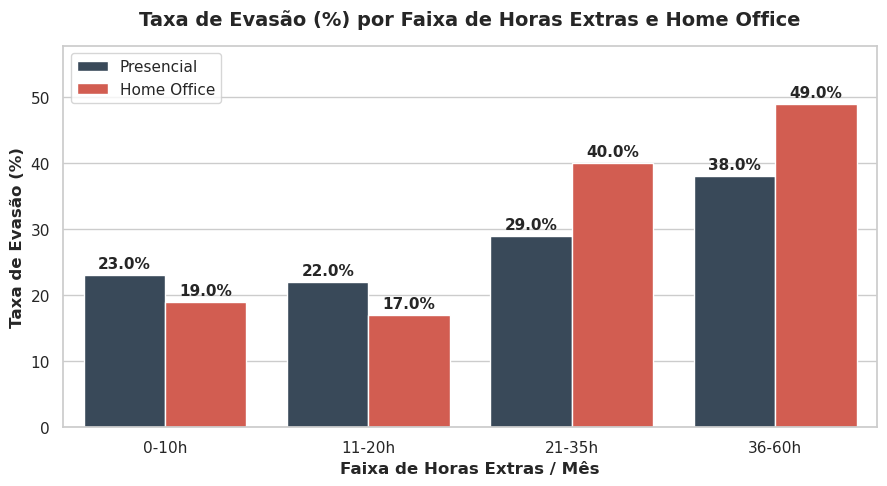

In [497]:
# Grafico de evasao por horas extras e home office
evasao_operacional['status_home_office'] = evasao_operacional['home_office'].map({True: 'Home Office', False: 'Presencial'})

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=evasao_operacional,
    x='faixa_horas_extras',
    y='% taxa_evasao',
    hue='status_home_office',
    palette=['#34495e', '#e74c3c']
)

plt.title('Taxa de Evasão (%) por Faixa de Horas Extras e Home Office', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Faixa de Horas Extras / Mês', fontweight='bold')
plt.ylabel('Taxa de Evasão (%)', fontweight='bold')
plt.legend(title='')
plt.ylim(0, evasao_operacional['% taxa_evasao'].max() * 1.18)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/evasao_horas_extras_home_office.png', dpi=300, bbox_inches='tight')
plt.show()

In [498]:
# Analise dos perfis mais desligados conforme nivel, promocao e horas extras

df_desligados = df_analise[df_analise['status_atual'] == 'Desligado'].copy()

df_desligados['perfil'] = (
    df_desligados['nivel'].astype(str) + ' | ' + 
    df_desligados['flag_promocao'].map({0: 'Sem Promoção', 1: 'Com Promoção'}) + ' | HE: ' + 
    df_desligados['faixa_horas_extras'].astype(str)
)

perfil_desligados = df_desligados['perfil'].value_counts().reset_index(name='total_demissoes')
perfil_desligados['%_dos_desligados'] = (perfil_desligados['total_demissoes'] / len(df_desligados) * 100).round(2)

display(perfil_desligados.head(10))

,perfil,total_demissoes,%_dos_desligados
0,Júnior | Sem Promoção | HE: 36-60h,42,23.73
1,Pleno | Sem Promoção | HE: 11-20h,41,23.16
2,Pleno | Sem Promoção | HE: 0-10h,34,19.21
3,Pleno | Sem Promoção | HE: 36-60h,27,15.25
4,Pleno | Sem Promoção | HE: 21-35h,13,7.34
5,Sênior | Com Promoção | HE: 11-20h,7,3.95
6,Sênior | Com Promoção | HE: 0-10h,7,3.95
7,Sênior | Com Promoção | HE: 21-35h,2,1.13
8,Pleno | Com Promoção | HE: 11-20h,1,0.56
9,Sênior | Com Promoção | HE: 36-60h,1,0.56


/tmp/ipykernel_3725/1196602901.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 

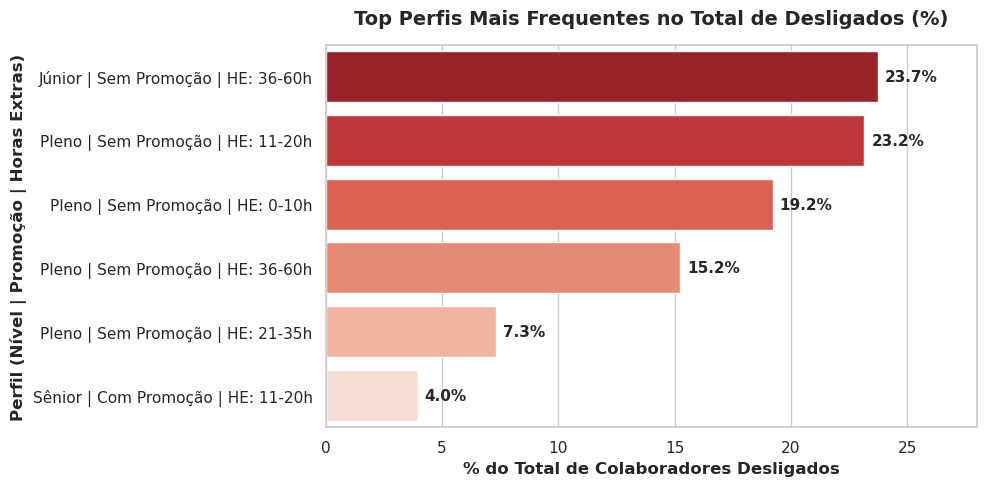

In [499]:
# Grafico
top_perfis = perfil_desligados.head(6)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=top_perfis,
    y='perfil',
    x='%_dos_desligados',
    palette='Reds_r'
)

plt.title('Top Perfis Mais Frequentes no Total de Desligados (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('% do Total de Colaboradores Desligados', fontweight='bold')
plt.ylabel('Perfil (Nível | Promoção | Horas Extras)', fontweight='bold')
plt.xlim(0, top_perfis['%_dos_desligados'].max() * 1.18)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=5, fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/analise_perfis_desligados1.png', dpi=300, bbox_inches='tight')
plt.show()

In [500]:
# Análise dos desligados conforme nivel, promoção, forma de trabalho
analise_desligados2 = df_analise[df_analise['status_atual'] == 'Desligado'].copy()

analise_desligados2['status_promocao'] = analise_desligados2['flag_promocao'].map({0: 'Sem Promoção', 1: 'Com Promoção'})
analise_desligados2['status_home'] = analise_desligados2['home_office'].map({True: 'Home Office', False: 'Presencial'})

analise_desligados2['perfil'] = (
    analise_desligados2['nivel'].astype(str) + ' | ' + 
    analise_desligados2['status_promocao'] + ' | ' + 
    analise_desligados2['status_home']
)

perfil_desligados = analise_desligados2['perfil'].value_counts().reset_index(name='total_demissoes')
perfil_desligados['%_dos_desligados'] = (perfil_desligados['total_demissoes'] / len(analise_desligados2) * 100).round(2)

display(perfil_desligados)

,perfil,total_demissoes,%_dos_desligados
0,Pleno | Sem Promoção | Presencial,66,37.29
1,Pleno | Sem Promoção | Home Office,49,27.68
2,Júnior | Sem Promoção | Presencial,25,14.12
3,Júnior | Sem Promoção | Home Office,18,10.17
4,Sênior | Com Promoção | Presencial,11,6.21
5,Sênior | Com Promoção | Home Office,6,3.39
6,Pleno | Com Promoção | Home Office,1,0.56
7,Sênior | Sem Promoção | Presencial,1,0.56


/tmp/ipykernel_3725/3303674302.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 

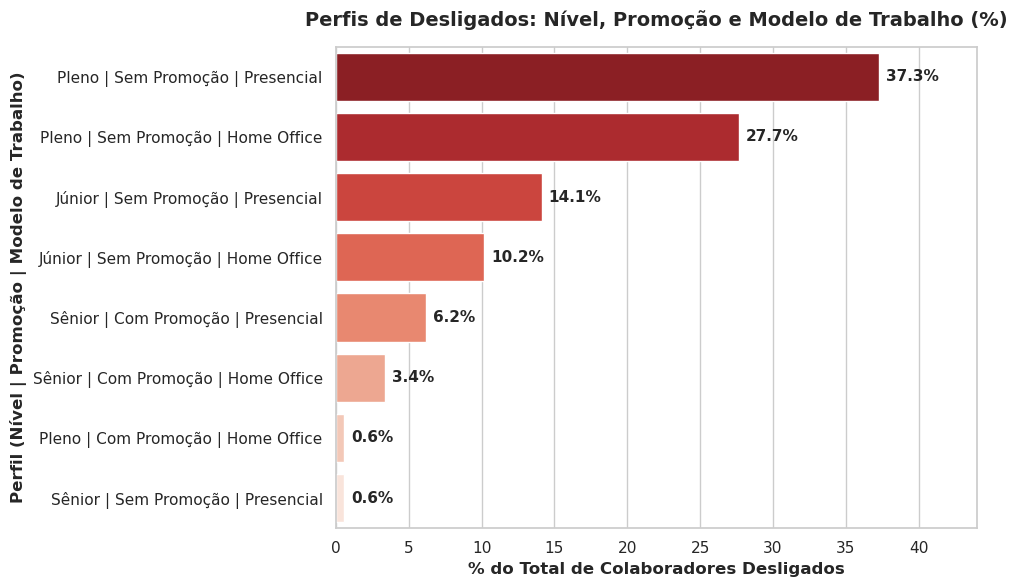

In [501]:
#Grafico
plt.figure(figsize=(10, max(6, len(perfil_desligados) * 0.5)))
ax = sns.barplot(
    data=perfil_desligados,
    y='perfil',
    x='%_dos_desligados',
    palette='Reds_r'
)

plt.title('Perfis de Desligados: Nível, Promoção e Modelo de Trabalho (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('% do Total de Colaboradores Desligados', fontweight='bold')
plt.ylabel('Perfil (Nível | Promoção | Modelo de Trabalho)', fontweight='bold')
plt.xlim(0, perfil_desligados['%_dos_desligados'].max() * 1.18)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=5, fontweight='bold')

plt.tight_layout()
plt.savefig('graficos/analise_perfis_desligados2.png', dpi=300, bbox_inches='tight')
plt.show()

In [502]:
df_analise.to_csv("dados_tratados.csv", index=False)